In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("semiconductor_wafer_defect_dataset.csv")

df.head()

,wafer_id,temperature_c,pressure_torr,gas_flow_sccm,etch_rate_nm_min,voltage_v,current_ma,process_step,defect_label
0,1,457.450712,747.287210,113.215053,93.852614,5.139314,20.341747,Deposition,0
1,2,447.926035,746.397577,116.945005,94.738753,5.113329,20.024511,Lithography,0
2,3,459.715328,706.130705,114.026189,95.514359,4.625392,19.137690,Deposition,0
3,4,472.845448,750.097294,121.104180,102.574892,5.231834,19.994947,Deposition,0
4,5,446.487699,781.984872,131.971785,89.022262,4.403967,20.981683,Deposition,0


In [ ]:
print("Ukuran dataset:", df.shape)

print("\nDaftar kolom:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()

Ukuran dataset: (5000, 9)

Daftar kolom:
['wafer_id', 'temperature_c', 'pressure_torr', 'gas_flow_sccm', 'etch_rate_nm_min', 'voltage_v', 'current_ma', 'process_step', 'defect_label']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   wafer_id          5000 non-null   int64  
 1   temperature_c     5000 non-null   float64
 2   pressure_torr     5000 non-null   float64
 3   gas_flow_sccm     5000 non-null   float64
 4   etch_rate_nm_min  5000 non-null   float64
 5   voltage_v         5000 non-null   float64
 6   current_ma        5000 non-null   float64
 7   process_step      5000 non-null   object 
 8   defect_label      5000 non-null   int64  
dtypes: float64(6), int64(2), object(1)
memory usage: 351.7+ KB


In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
wafer_id,5000.0,NaN,NaN,NaN,2500.5,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
temperature_c,5000.0,NaN,NaN,NaN,450.084029,14.947197,401.38099,440.131424,450.201984,459.990159,508.893566
pressure_torr,5000.0,NaN,NaN,NaN,759.703783,30.313113,642.327992,739.402513,759.476484,780.317142,865.871656
gas_flow_sccm,5000.0,NaN,NaN,NaN,120.10553,9.987698,86.244209,113.391136,120.099174,126.755342,154.289105
etch_rate_nm_min,5000.0,NaN,NaN,NaN,95.132121,8.026693,64.148997,89.682554,95.154073,100.652917,130.832674
voltage_v,5000.0,NaN,NaN,NaN,4.992659,0.39335,3.537965,4.719296,4.996793,5.260243,6.44454
current_ma,5000.0,NaN,NaN,NaN,19.986853,1.998921,13.093292,18.601549,19.997914,21.354883,27.383249
process_step,5000,5,CMP,1029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
defect_label,5000.0,NaN,NaN,NaN,0.0014,0.037394,0.0,0.0,0.0,0.0,1.0


In [ ]:
print("Missing value setiap kolom:")
print(df.isnull().sum())

print("\nJumlah data duplikat:")
print(df.duplicated().sum())

Missing value setiap kolom:
wafer_id            0
temperature_c       0
pressure_torr       0
gas_flow_sccm       0
etch_rate_nm_min    0
voltage_v           0
current_ma          0
process_step        0
defect_label        0
dtype: int64

Jumlah data duplikat:
0


defect_label
0    4993
1       7
Name: count, dtype: int64


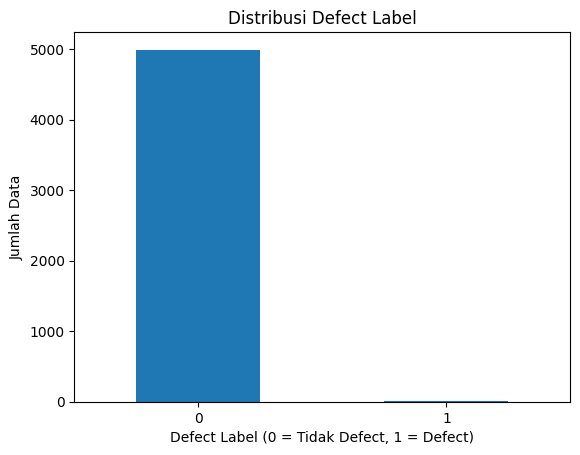

In [ ]:
print(df["defect_label"].value_counts())

df["defect_label"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.title("Distribusi Defect Label")
plt.xlabel("Defect Label (0 = Tidak Defect, 1 = Defect)")
plt.ylabel("Jumlah Data")
plt.show()

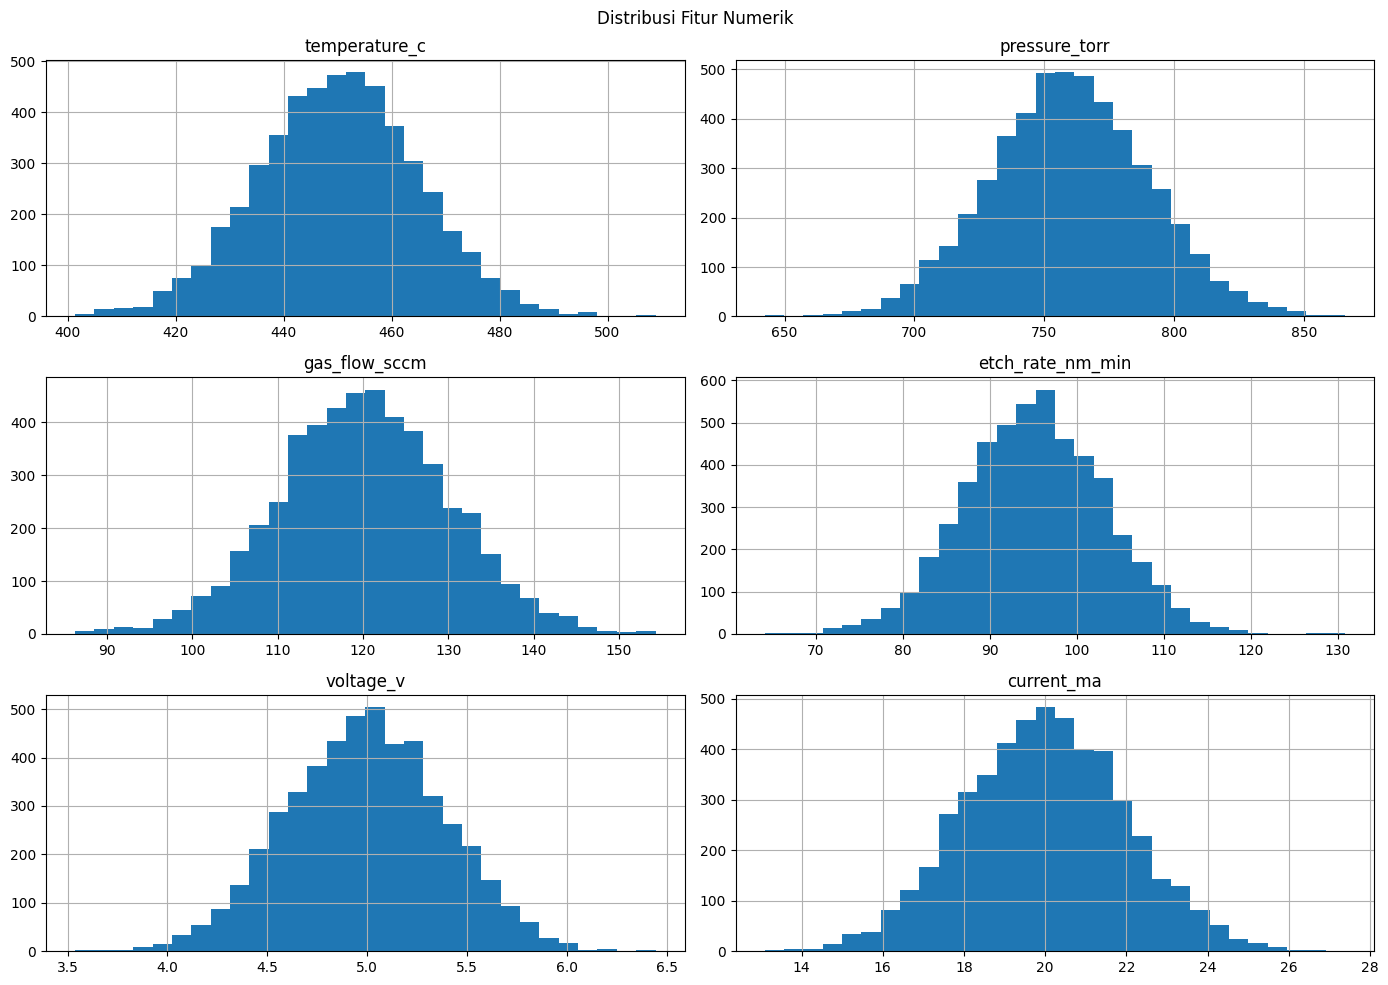

In [ ]:
numeric_cols = [
    "temperature_c",
    "pressure_torr",
    "gas_flow_sccm",
    "etch_rate_nm_min",
    "voltage_v",
    "current_ma"
]

df[numeric_cols].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle("Distribusi Fitur Numerik")
plt.tight_layout()
plt.show()

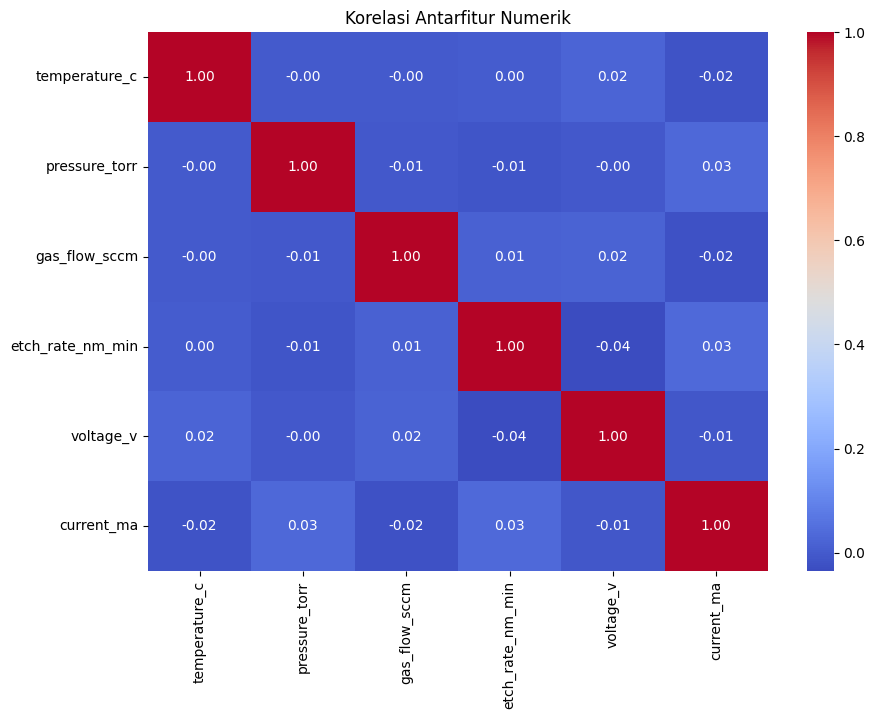

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Korelasi Antarfitur Numerik")
plt.show()

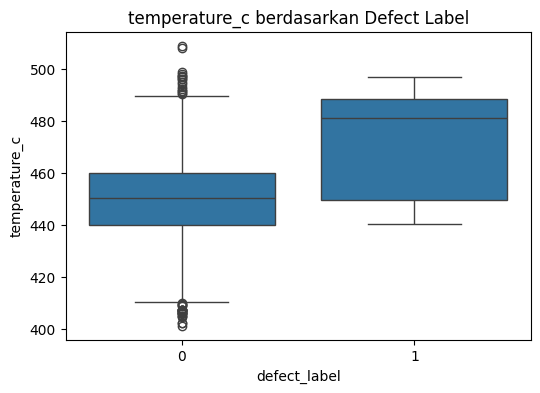

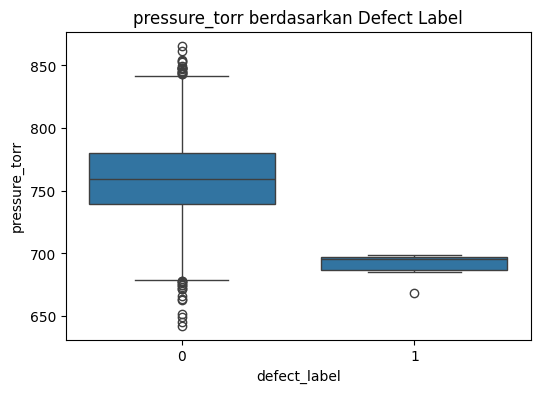

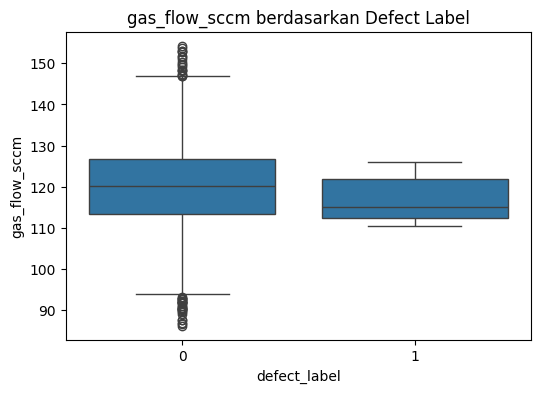

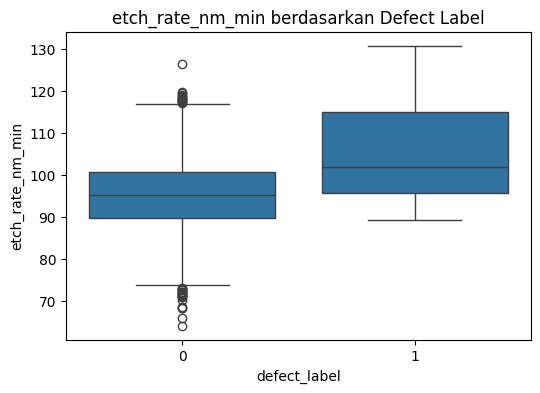

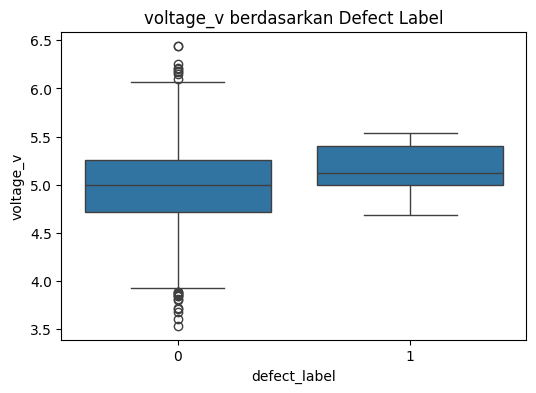

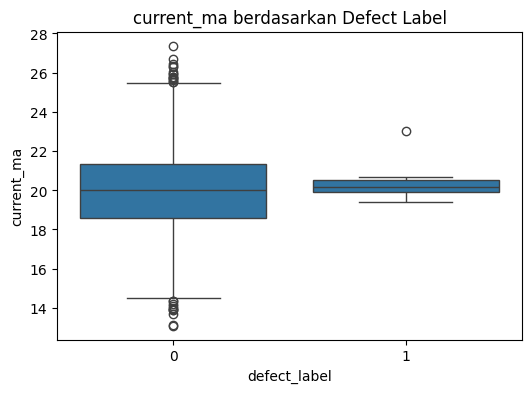

In [ ]:
for col in numeric_cols:
    plt.figure(figsize=(6, 4))

    sns.boxplot(
        data=df,
        x="defect_label",
        y=col
    )

    plt.title(f"{col} berdasarkan Defect Label")
    plt.show()

In [ ]:

df_clean = df.copy()

# Periksa kondisi awal
print("Ukuran dataset:", df_clean.shape)
print("Total missing value:", df_clean.isnull().sum().sum())
print("Total data duplikat:", df_clean.duplicated().sum())
print("Missing value per kolom:")
print(df_clean.isnull().sum())

Ukuran dataset: (5000, 9)
Total missing value: 0
Total data duplikat: 0
Missing value per kolom:
wafer_id            0
temperature_c       0
pressure_torr       0
gas_flow_sccm       0
etch_rate_nm_min    0
voltage_v           0
current_ma          0
process_step        0
defect_label        0
dtype: int64


In [ ]:
# Pisahkan kolom numerik dan kategorikal
numeric_cols = df_clean.select_dtypes(include="number").columns.tolist()
categorical_cols = df_clean.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Isi missing value numerik dengan median
for col in numeric_cols:
    if col not in ["wafer_id", "defect_label"]:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Isi missing value kategorikal dengan modus
for col in categorical_cols:
    mode_value = df_clean[col].mode(dropna=True)

    if not mode_value.empty:
        df_clean[col] = df_clean[col].fillna(mode_value.iloc[0])

print("Missing value setelah preprocessing:")
print(df_clean.isnull().sum())

Missing value setelah preprocessing:
wafer_id            0
temperature_c       0
pressure_torr       0
gas_flow_sccm       0
etch_rate_nm_min    0
voltage_v           0
current_ma          0
process_step        0
defect_label        0
dtype: int64


In [ ]:
print(df_clean["defect_label"].value_counts(dropna=False))
print(df_clean["defect_label"].dtype)

defect_label
0    4993
1       7
Name: count, dtype: int64
int64


In [ ]:
df_clean = df_clean.dropna(subset=["defect_label"])
df_clean["defect_label"] = df_clean["defect_label"].astype(int)

print("Ukuran akhir preprocessing:", df_clean.shape)

Ukuran akhir preprocessing: (5000, 9)


In [ ]:
df_featured = df_clean.copy()

if {"voltage_v", "current_ma"}.issubset(df_featured.columns):
    df_featured["electrical_power_mw"] = (
        df_featured["voltage_v"] * df_featured["current_ma"]
    )

print("Kolom setelah feature engineering:")
print(df_featured.columns.tolist())

df_featured.head()

Kolom setelah feature engineering:
['wafer_id', 'temperature_c', 'pressure_torr', 'gas_flow_sccm', 'etch_rate_nm_min', 'voltage_v', 'current_ma', 'process_step', 'defect_label', 'electrical_power_mw']


,wafer_id,temperature_c,pressure_torr,gas_flow_sccm,etch_rate_nm_min,voltage_v,current_ma,process_step,defect_label,electrical_power_mw
0,1,457.450712,747.287210,113.215053,93.852614,5.139314,20.341747,Deposition,0,104.542636
1,2,447.926035,746.397577,116.945005,94.738753,5.113329,20.024511,Lithography,0,102.391921
2,3,459.715328,706.130705,114.026189,95.514359,4.625392,19.137690,Deposition,0,88.519319
3,4,472.845448,750.097294,121.104180,102.574892,5.231834,19.994947,Deposition,0,104.610236
4,5,446.487699,781.984872,131.971785,89.022262,4.403967,20.981683,Deposition,0,92.402639


In [ ]:
df_featured = df_featured.drop(
    columns=["wafer_id"],
    errors="ignore"
)

print("Kolom dataset hasil feature engineering:")
print(df_featured.columns.tolist())

print("Ukuran dataset:", df_featured.shape)

Kolom dataset hasil feature engineering:
['temperature_c', 'pressure_torr', 'gas_flow_sccm', 'etch_rate_nm_min', 'voltage_v', 'current_ma', 'process_step', 'defect_label', 'electrical_power_mw']
Ukuran dataset: (5000, 9)


In [ ]:
df_clean.to_csv(
    "semiconductor_wafer_defect_clean.csv",
    index=False
)

df_featured.to_csv(
    "semiconductor_wafer_defect_featured.csv",
    index=False
)

print("Dataset bersih berhasil disimpan!")
print("Dataset feature engineering berhasil disimpan!")

Dataset bersih berhasil disimpan!
Dataset feature engineering berhasil disimpan!


In [ ]:
from google.colab import files

files.download("semiconductor_wafer_defect_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("=== VALIDASI DATASET BERSIH ===")
print("Ukuran:", df_clean.shape)
print("Missing value:", df_clean.isnull().sum().sum())
print("Duplikat:", df_clean.duplicated().sum())

print("\n=== VALIDASI DATASET FEATURED ===")
print("Ukuran:", df_featured.shape)
print("Missing value:", df_featured.isnull().sum().sum())
print("Duplikat:", df_featured.duplicated().sum())

print("\n=== DISTRIBUSI TARGET ===")
print(df_featured["defect_label"].value_counts())

=== VALIDASI DATASET BERSIH ===
Ukuran: (5000, 9)
Missing value: 0
Duplikat: 0

=== VALIDASI DATASET FEATURED ===
Ukuran: (5000, 9)
Missing value: 0
Duplikat: 0

=== DISTRIBUSI TARGET ===
defect_label
0    4993
1       7
Name: count, dtype: int64


In [ ]:
df_featured = df_clean.copy()

# Membuat fitur daya listrik
if {"voltage_v", "current_ma"}.issubset(df_featured.columns):
    df_featured["electrical_power_mw"] = (
        df_featured["voltage_v"] * df_featured["current_ma"]
    )

df_featured.head()

,wafer_id,temperature_c,pressure_torr,gas_flow_sccm,etch_rate_nm_min,voltage_v,current_ma,process_step,defect_label,electrical_power_mw
0,1,457.450712,747.287210,113.215053,93.852614,5.139314,20.341747,Deposition,0,104.542636
1,2,447.926035,746.397577,116.945005,94.738753,5.113329,20.024511,Lithography,0,102.391921
2,3,459.715328,706.130705,114.026189,95.514359,4.625392,19.137690,Deposition,0,88.519319
3,4,472.845448,750.097294,121.104180,102.574892,5.231834,19.994947,Deposition,0,104.610236
4,5,446.487699,781.984872,131.971785,89.022262,4.403967,20.981683,Deposition,0,92.402639


In [ ]:
df_featured = df_featured.drop(
    columns=["wafer_id"],
    errors="ignore"
)

print(df_featured.columns.tolist())
print(df_featured.shape)

['temperature_c', 'pressure_torr', 'gas_flow_sccm', 'etch_rate_nm_min', 'voltage_v', 'current_ma', 'process_step', 'defect_label', 'electrical_power_mw']
(5000, 9)


In [ ]:
df_featured.to_csv(
    "semiconductor_wafer_defect_featured.csv",
    index=False
)

print("Dataset final berhasil disimpan!")

Dataset final berhasil disimpan!


In [ ]:
X = df_featured.drop(columns=["defect_label"])
y = df_featured["defect_label"]

print("Jumlah fitur:", X.shape)
print("Jumlah target:", y.shape)

Jumlah fitur: (5000, 8)
Jumlah target: (5000,)


In [ ]:
%%writefile preprocessing.py
import pandas as pd

def load_data(path):
    df = pd.read_csv(path)
    df = df.drop_duplicates()
    return df

def feature_engineering(df):
    df = df.copy()

    if {"voltage_v", "current_ma"}.issubset(df.columns):
        df["electrical_power_mw"] = (
            df["voltage_v"] * df["current_ma"]
        )

    df = df.drop(columns=["wafer_id"], errors="ignore")
    return df

def split_features_target(df):
    X = df.drop(columns=["defect_label"])
    y = df["defect_label"]
    return X, y

Overwriting preprocessing.py


In [ ]:
from google.colab import files

files.download("semiconductor_wafer_defect_featured.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("preprocessing.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>